In [ ]:
import json
import os

import agama
import gizmo_analysis as gizmo
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

agama.setUnits(mass=1, length=1, velocity=1)
units = agama.getUnits()

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 10
MEDIUM_SIZE = 10
BIGGER_SIZE = 10

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [2]:
sim_dir = "/Users/z5114326/Documents/simulations/"
# sim_dir = "/Volumes/Expansion/simulations/"
sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]

sim_codes = sim_dir + "simulation_codes.json"
with open(sim_codes) as sim_json:
    sim_data = json.load(sim_json)

scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

dat_dir = "../data/"
mw_gcs_fil = "mw_gcs/mw_gcs.csv"
mw_gcs = pd.read_csv(dat_dir + mw_gcs_fil)

pot_path = "../.venv312/lib/python3.12/site-packages/agama/data/"

In [12]:
public_snapshot_file = sim_dir + "snapshot_times_public.txt"
pub_data = pd.read_table(public_snapshot_file, comment="#", header=None, sep=r"\s+")
pub_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
timez0 = float(pub_data[pub_data["index"] == 600]["time_Gyr"].values[0])
pub_snaps = np.array(pub_data["index"])
pub_times = np.array(pub_data["time_Gyr"])

pub_times = pub_times[pub_snaps > 100]
pub_snaps = pub_snaps[pub_snaps > 100]
pub_snaps

array([102, 120, 142, 172, 214, 277, 294, 312, 332, 356, 382, 412, 446,
       486, 534, 590, 591, 592, 593, 594, 595, 596, 597, 598, 599, 600])

In [17]:
dat = {sim: [] for sim in sim_lst}

for snap in pub_snaps:
    for sim in sim_lst:
        ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
        ghost_data = h5py.File(ghost_file, "r")

        pot_file = sim_dir + sim + "/potentials/snap_%d/combined_snap_%d.ini" % (snap, snap)
        pot_nbody = agama.Potential(pot_file)

        dat[sim].append(np.abs(pot_nbody.potential([0, 0, 0])))

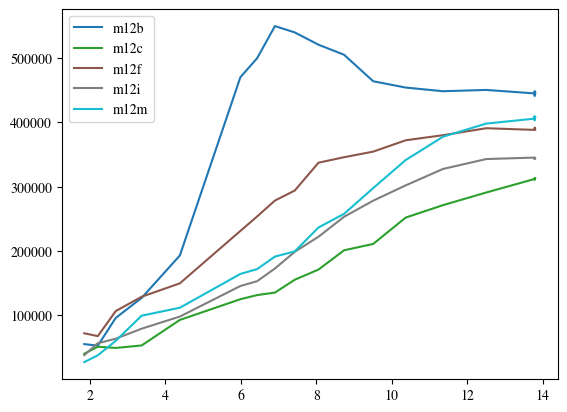

In [22]:
for sim in sim_lst:
    plt.plot(pub_times, dat[sim], c=sim_colors[sim], label=sim)

plt.legend()